# Operaciones de aprendizaje automático
## Maestría en Inteligencia Artificial Aplicada

### TC5061 | Proyecto MiBici: propuesta y base reproducible | Colaborativo

#### **Equipo:** 7
#### **Nombre:** Luis Arturo Sánchez Davila
#### **Matrícula:** A01840576

## Objetivo
Notebook del **modelo base de P3 (clustering)**: ¿qué grupos de estaciones comparten patrones de uso y dónde se ubican? Entrena un K-Means sobre el perfil de uso de cada estación, lo evalúa (métricas internas, estabilidad e interpretación) y lo registra en MLflow como el piso contra el que se comparan las alternativas (`0.08-lasd-mejoramodelo-p3`).

## Entradas y salidas
- **Entrada:** `data/processed/viajes_modelado_AAAA-MM_AAAA-MM.parquet` (`0.06-lasd-limpieza-p3`) y la nomenclatura de estaciones.
- **Salidas:**
  - `data/processed/p3_caracteristicas_train.parquet`, `p3_caracteristicas_valid.parquet` y `p3_baseline.json`: variables por estación y métricas del baseline, que usa `0.08-lasd-mejoramodelo-p3`.
  - Run `baseline` del experimento `p3` en MLflow y los archivos `reports/figures/p3_*`.

## Nota de reproducibilidad
El notebook se ejecuta desde la carpeta `notebooks/`. Las cifras corresponden a la corrida del 15-oct-2026 con los 81 meses del rango. La celda 4.4 escribe en el servidor de MLflow del equipo; `REGISTRAR_EN_MLFLOW = False` la desactiva.

## Serie de notebooks de P3
| Notebook | Contenido | Entrega |
|---|---|---|
| `0.03-lasd-exploracion-carga` | Paso 1: carga y descripción | Dataset normalizado en `data/interim/` |
| `0.05-lasd-eda-p3` | Paso 2: análisis exploratorio | Hallazgos de calidad, tiempo y estaciones |
| `0.06-lasd-limpieza-p3` | Paso 3: limpieza, partición y preprocesamiento | `data/processed/` (viajes de modelado, estaciones y demanda) |
| `0.07-lasd-baseline-p3` | Paso 4 (4.1 a 4.4): modelo base y registro en MLflow | Variables por estación y métricas del baseline |
| `0.08-lasd-mejoramodelo-p3` | Paso 4 (4.5 a 4.9): modelo alternativo y registro en MLflow | Comparación contra el baseline |

In [1]:
# Importación de librerías y registro de versiones (evidencia de reproducibilidad)
from pathlib import Path
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow
import sklearn

print("Python      :", sys.version.split()[0])
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("pyarrow     :", pyarrow.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib  :", matplotlib.__version__)

Python      : 3.11.9
pandas      : 3.0.5
numpy       : 1.26.4
pyarrow     : 25.0.1
scikit-learn: 1.5.2
matplotlib  : 3.11.2


## Configuración y entradas

Las rutas, el rango, la semilla y la paleta salen de `tc5061_proyecto_equipo07/config.py`. Se carga el dataset de modelado con la partición temporal y la nomenclatura de estaciones.

In [2]:
# Configuración compartida (el notebook se ejecuta desde notebooks/)
try:
    from tc5061_proyecto_equipo07 import dataset
except ModuleNotFoundError:  # paquete sin instalar; `make requirements` lo instala con `-e .`
    sys.path.insert(0, str(Path.cwd().parent))
    from tc5061_proyecto_equipo07 import dataset

from tc5061_proyecto_equipo07.config import (
    AZUL,
    FIGURES_DIR,
    MES_FIN,
    MES_INICIO,
    NARANJA,
    PROCESSED_DATA_DIR,
    PROJ_ROOT,
    RUTA_ESTACIONES_CRUDAS,
    SEMILLA,
    VERDE,
)

# Opciones de visualización de pandas
pd.set_option("display.max_columns", None)   # mostrar todas las columnas
pd.set_option("display.max_colwidth", None)  # no recortar textos largos

PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Entrada: viajes limpios con partición temporal (0.06-lasd-limpieza-p3)
RUTA_VIAJES_MODELADO = PROCESSED_DATA_DIR / f"viajes_modelado_{MES_INICIO}_{MES_FIN}.parquet"
if not RUTA_VIAJES_MODELADO.exists():
    raise FileNotFoundError(f"Falta {RUTA_VIAJES_MODELADO.name}; ejecutar antes 0.06-lasd-limpieza-p3")
limpios = pd.read_parquet(RUTA_VIAJES_MODELADO)

# Nomenclatura de estaciones (misma detección de codificación que los viajes)
ruta_nomenclatura = sorted(RUTA_ESTACIONES_CRUDAS.glob("nomenclatura_*.csv"))[-1]
nomenclatura = pd.read_csv(ruta_nomenclatura,
                           encoding=dataset.detectar_codificacion(ruta_nomenclatura.read_bytes()))
print(f"Viajes de modelado: {len(limpios):,} | estaciones en la nomenclatura: {len(nomenclatura)}")
print(limpios["particion"].value_counts().reindex(["train", "valid", "test", "brecha"]).to_string())

2026-10-15 21:37:14.172 | INFO     | tc5061_proyecto_equipo07.config:<module>:14 - PROJ_ROOT path is: /Users/lsanchez/Maestria_proyectos/MLOps-ProyectoMiBici-Equipo7


Viajes de modelado: 27,026,645 | estaciones en la nomenclatura: 484
particion
train     17987077
valid      4520744
test       4489362
brecha       29462


## Paso 4 - P3 - Clustering: modelo base

**Pregunta:** ¿qué grupos de estaciones comparten patrones de uso y dónde se ubican?
**Usuario y decisión:** planeación urbana y expansión; decide dónde ampliar capacidad, qué estaciones reubicar y qué reglas de rebalanceo aplicar por grupo.

### 4.1 Diseño del modelo base

| Elemento | Decisión |
|---|---|
| **Unidad** | Una fila por estación |
| **Datos** | Solo viajes del conjunto de **entrenamiento** (2020-01 a 2024-09), ya limpios |
| **Filtro** | Estaciones con al menos `MIN_SALIDAS_TRAIN` salidas: con pocos viajes el perfil horario es ruido |
| **Variables** | Perfil horario laboral y de fin de semana (20 horas de servicio cada uno, como proporción de las salidas de la estación), volumen diario, balance neto sobre salidas, proporción de viajes circulares y duración mediana |
| **Preparación** | Estandarización con parámetros ajustados en entrenamiento |
| **Algoritmo** | K-Means; `k` entre 2 y 10, elegido por el mayor coeficiente de silueta |
| **Evaluación** | Silueta, Davies-Bouldin, Calinski-Harabasz, estabilidad (ARI) al reasignar con el año de validación e interpretación de cada grupo |

**Qué se excluye y por qué:**
- **Latitud y longitud no entran al clustering:** si entraran, los grupos serían geográficos y no por uso. Se usan después para ubicar cada grupo.
- **Horas 1:00 a 4:59:** el servicio no opera; son columnas casi constantes.
- **Estaciones nuevas (sin historia en train):** no pueden agruparse con datos de entrenamiento. Se asignan después al grupo más cercano con la información que tengan.

Es un **baseline**: define el piso con la configuración más simple (K-Means sobre variables estandarizadas), contra el cual se compararán las alternativas (HDBSCAN, PCA previo, otro conjunto de variables).

In [3]:
# Librerías del modelado y parámetros del modelo base
import subprocess
import warnings
import hashlib
import json

from sklearn.cluster import KMeans
from sklearn.metrics import (adjusted_rand_score, calinski_harabasz_score,
                             davies_bouldin_score, silhouette_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# numpy 2.2 con Accelerate (macOS) emite RuntimeWarning falsos en matmul con datos finitos;
# la finitud se verifica con un assert más abajo
warnings.filterwarnings("ignore", category=RuntimeWarning, module="sklearn.utils.extmath")

MIN_SALIDAS_TRAIN = 1000    # estaciones con menos salidas en train no se agrupan
MIN_SALIDAS_VALID = 300     # estaciones con menos salidas en valid no entran a la prueba de estabilidad
K_MINIMO, K_MAXIMO = 2, 10
HORAS_SERVICIO = [hora for hora in range(24) if hora not in (1, 2, 3, 4)]

In [4]:
# Variables por estación a partir de los viajes de un periodo
def perfil_de_estaciones(viajes_periodo):
    """Regresa una fila por estación con su perfil horario y sus indicadores de uso."""
    inicio = viajes_periodo["inicio_del_viaje"]
    base = pd.DataFrame({
        "estacion": viajes_periodo["origen_id"].to_numpy(),
        "hora": inicio.dt.hour.to_numpy(),
        "laboral": (inicio.dt.dayofweek < 5).to_numpy(),
    })
    conteo = (base.groupby(["estacion", "laboral", "hora"]).size()
              .unstack("hora", fill_value=0).reindex(columns=HORAS_SERVICIO, fill_value=0))
    estaciones_ids = conteo.index.get_level_values("estacion").unique()

    def perfil(es_laboral, prefijo):
        bloque = conteo.xs(es_laboral, level="laboral").reindex(estaciones_ids, fill_value=0)
        proporcion = bloque.div(bloque.sum(axis=1).replace(0, np.nan), axis=0).fillna(0)
        proporcion.columns = [f"{prefijo}_h{hora:02d}" for hora in proporcion.columns]
        return proporcion

    perfiles = pd.concat([perfil(True, "lab"), perfil(False, "fin")], axis=1)

    salidas = viajes_periodo["origen_id"].value_counts()
    llegadas = viajes_periodo["destino_id"].value_counts()
    dias_activos = (pd.DataFrame({"estacion": viajes_periodo["origen_id"].to_numpy(),
                                  "dia": inicio.dt.floor("D").to_numpy()})
                    .groupby("estacion")["dia"].nunique())
    circulares = (viajes_periodo["origen_id"] == viajes_periodo["destino_id"]).groupby(
        viajes_periodo["origen_id"]).mean()
    duracion = viajes_periodo.groupby("origen_id", observed=True)["duracion_min"].median()

    indicadores = pd.DataFrame({
        "salidas": salidas,
        "log_viajes_por_dia": np.log1p(salidas / dias_activos),
        "neto_sobre_salidas": (llegadas.reindex(salidas.index).fillna(0) - salidas) / salidas,
        "prop_circulares": circulares,
        "duracion_mediana_min": duracion,
    }).reindex(estaciones_ids)
    indicadores.index = indicadores.index.astype(int)
    perfiles.index = perfiles.index.astype(int)
    return perfiles.join(indicadores)

caracteristicas_train = perfil_de_estaciones(limpios[limpios["particion"] == "train"])
caracteristicas_train = caracteristicas_train[caracteristicas_train["salidas"] >= MIN_SALIDAS_TRAIN]

COLUMNAS_MODELO = [c for c in caracteristicas_train.columns if c != "salidas"]
X_train = caracteristicas_train[COLUMNAS_MODELO]

print("Estaciones agrupadas (>= %d salidas en train): %d" % (MIN_SALIDAS_TRAIN, len(X_train)))
print("Variables por estación:", len(COLUMNAS_MODELO))
print("Nulos en las variables:", int(X_train.isna().sum().sum()))
X_train[["log_viajes_por_dia", "neto_sobre_salidas", "prop_circulares", "duracion_mediana_min"]].describe().T.round(3)

Estaciones agrupadas (>= 1000 salidas en train): 362
Variables por estación: 44
Nulos en las variables: 0


,count,mean,std,min,25%,50%,75%,max
log_viajes_por_dia,362.0,3.166714,0.77968,1.447176,2.548877,3.177078,3.748612,5.398296
neto_sobre_salidas,362.0,-0.002027,0.250182,-0.458407,-0.179012,-0.029256,0.104986,1.417283
prop_circulares,362.0,0.078694,0.02499,0.033106,0.063084,0.075096,0.086465,0.303059
duracion_mediana_min,362.0,9.792703,2.066125,3.983333,8.604167,9.633333,11.0,17.516667


### 4.2 Entrenamiento y elección de `k`

Se ajusta K-Means para cada `k` entre 2 y 10, con el mismo escalador (ajustado en entrenamiento) y la misma semilla. Se elige el `k` de mayor coeficiente de silueta. Se calculan además Davies-Bouldin (menor es mejor) y Calinski-Harabasz (mayor es mejor), para no depender de una sola métrica.

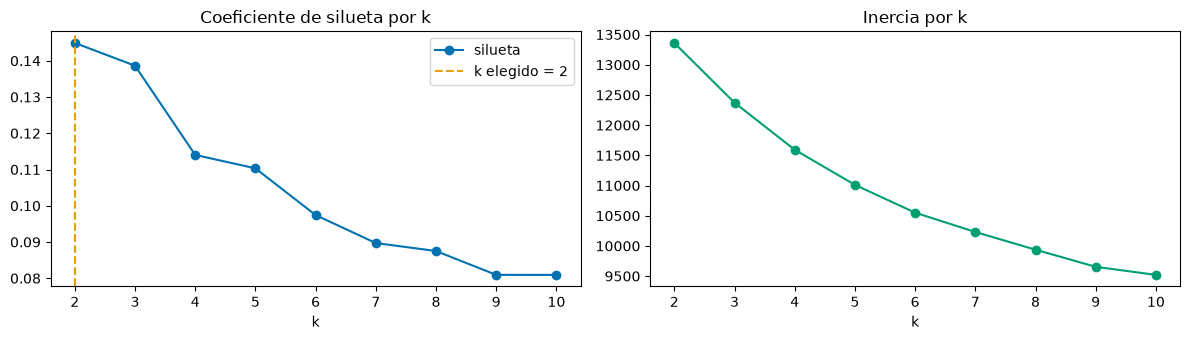

k elegido por silueta: 2


,silueta,davies_bouldin,calinski_harabasz,inercia,tam_min
k,,,,,
2,0.145,2.119,69.157,13361.263,160
3,0.139,2.265,51.590,12372.124,68
4,0.114,2.045,44.633,11592.239,22
5,0.110,1.985,39.853,11011.127,17
6,0.097,2.234,36.287,10550.767,19
7,0.090,2.026,32.950,10230.613,5
8,0.088,2.103,30.489,9937.113,17
9,0.081,2.205,28.676,9654.078,16
10,0.081,2.225,26.327,9519.917,9


In [5]:
# Ajuste de K-Means para cada k y selección por silueta
escalador = StandardScaler().fit(X_train)
Z_train = escalador.transform(X_train)
assert np.isfinite(Z_train).all(), "variables escaladas con valores no finitos"

resultados_k = []
for k in range(K_MINIMO, K_MAXIMO + 1):
    modelo_k = KMeans(n_clusters=k, n_init=10, random_state=SEMILLA).fit(Z_train)
    resultados_k.append({
        "k": k,
        "silueta": silhouette_score(Z_train, modelo_k.labels_),
        "davies_bouldin": davies_bouldin_score(Z_train, modelo_k.labels_),
        "calinski_harabasz": calinski_harabasz_score(Z_train, modelo_k.labels_),
        "inercia": modelo_k.inertia_,
        "tam_min": int(np.bincount(modelo_k.labels_).min()),
    })
resultados_k = pd.DataFrame(resultados_k).set_index("k")
K_ELEGIDO = int(resultados_k["silueta"].idxmax())

fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5))
resultados_k["silueta"].plot(marker="o", ax=ejes[0], color=AZUL)
ejes[0].axvline(K_ELEGIDO, color=NARANJA, linestyle="--", label=f"k elegido = {K_ELEGIDO}")
ejes[0].set_title("Coeficiente de silueta por k")
ejes[0].set_xlabel("k")
ejes[0].legend()
resultados_k["inercia"].plot(marker="o", ax=ejes[1], color=VERDE)
ejes[1].set_title("Inercia por k")
ejes[1].set_xlabel("k")
plt.tight_layout()
plt.show()

print("k elegido por silueta:", K_ELEGIDO)
resultados_k.round(3)

In [6]:
# Modelo base: escalador + K-Means con el k elegido (un solo objeto para registrar y reutilizar)
modelo_base = Pipeline([
    ("escalador", StandardScaler()),
    ("kmeans", KMeans(n_clusters=K_ELEGIDO, n_init=10, random_state=SEMILLA)),
]).fit(X_train)

etiquetas_train = modelo_base.named_steps["kmeans"].labels_
caracteristicas_train = caracteristicas_train.assign(grupo=etiquetas_train)

tamanos = pd.Series(etiquetas_train).value_counts().sort_index()
print("Estaciones por grupo:", tamanos.to_dict())

Estaciones por grupo: {0: 202, 1: 160}


**Observaciones del entrenamiento:**
- **Selección de `k`:** la silueta es máxima en `k = 2` (0.145) y baja al aumentar `k` (0.139 con 3, 0.114 con 4 y 0.081 con 10). Davies-Bouldin, en cambio, es mejor en `k = 5` (1.985): las métricas no coinciden y ningún `k` destaca con claridad.
- **Calidad del agrupamiento:** una silueta de 0.145 indica estructura débil: los grupos se solapan y las estaciones no forman conglomerados bien separados. Davies-Bouldin es 2.12 y Calinski-Harabasz, 69.2. Es el piso con el que se compararán las alternativas.
- **Tamaño de los grupos:** 362 estaciones agrupadas (las otras 122 de la nomenclatura tienen menos de 1,000 salidas en train o ninguna). Con `k = 2` quedan 202 y 160 estaciones; desde `k = 4` aparecen grupos de 22 estaciones o menos (5 con `k = 7`), poco útiles para decidir.

### 4.3 Evaluación

Además de las métricas internas, se evalúan dos cosas que importan para planeación:
- **Estabilidad:** ¿los grupos se sostienen en otro periodo? Se calculan las mismas variables con los viajes del año de **validación** (2024-10 a 2025-09), se asigna cada estación al grupo más cercano con el modelo ajustado en entrenamiento y se compara con su grupo original (índice de Rand ajustado: 1 = idéntico, 0 = azar).
- **Interpretabilidad:** un grupo solo sirve si se le puede nombrar; se describe su perfil horario y su ubicación.

In [7]:
# Estabilidad: reasignación de las estaciones con las variables calculadas en el año de validación
caracteristicas_valid = perfil_de_estaciones(limpios[limpios["particion"] == "valid"])
caracteristicas_valid = caracteristicas_valid[caracteristicas_valid["salidas"] >= MIN_SALIDAS_VALID]
comunes = caracteristicas_train.index.intersection(caracteristicas_valid.index)

grupo_original = caracteristicas_train.loc[comunes, "grupo"]
grupo_en_valid = modelo_base.predict(caracteristicas_valid.loc[comunes, COLUMNAS_MODELO])
ari_valid = adjusted_rand_score(grupo_original, grupo_en_valid)

# Métricas internas del modelo elegido
fila_elegida = resultados_k.loc[K_ELEGIDO]
metricas = {
    "silueta": float(fila_elegida["silueta"]),
    "davies_bouldin": float(fila_elegida["davies_bouldin"]),
    "calinski_harabasz": float(fila_elegida["calinski_harabasz"]),
    "inercia": float(fila_elegida["inercia"]),
    "ari_valid": float(ari_valid),
    "estaciones_train": int(len(X_train)),
    "estaciones_estabilidad": int(len(comunes)),
    "estaciones_cambian_de_grupo": int((grupo_original.to_numpy() != grupo_en_valid).sum()),
    "tam_grupo_min": int(tamanos.min()),
    "tam_grupo_max": int(tamanos.max()),
}
pd.Series(metricas).to_frame("valor")

,valor
silueta,0.144915
davies_bouldin,2.119360
calinski_harabasz,69.157043
inercia,13361.262717
ari_valid,0.656071
estaciones_train,362.000000
estaciones_estabilidad,359.000000
estaciones_cambian_de_grupo,34.000000
tam_grupo_min,160.000000
tam_grupo_max,202.000000


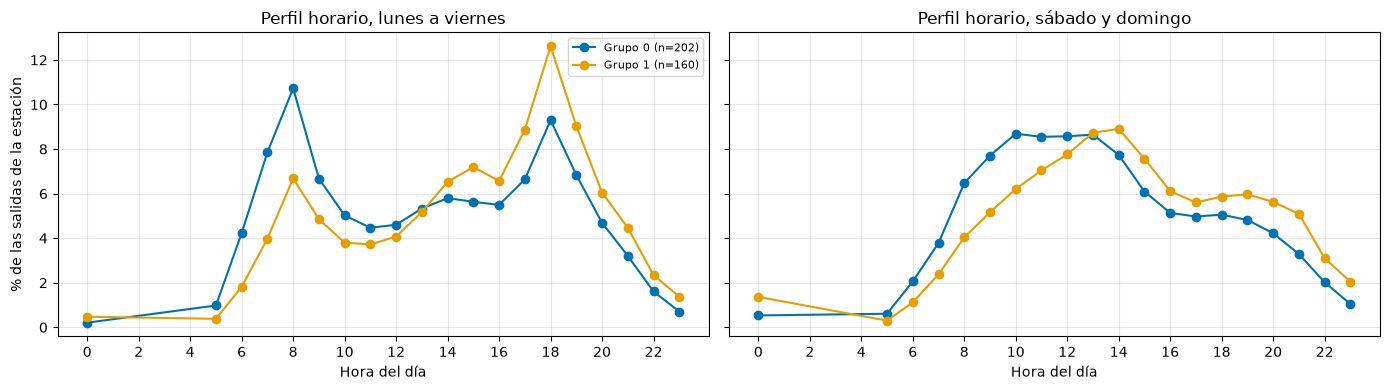

,estaciones,salidas_medianas,viajes_por_dia,neto_sobre_salidas,prop_circulares,duracion_mediana_min,capacidad_mediana
grupo,,,,,,,
0,202,26236.0,19.841,0.029,0.08,9.625,15.0
1,160,51004.0,29.422,-0.093,0.071,9.633,15.0


In [8]:
# Interpretación: perfil horario medio por grupo y características de cada grupo
columnas_lab = [c for c in COLUMNAS_MODELO if c.startswith("lab_")]
columnas_fin = [c for c in COLUMNAS_MODELO if c.startswith("fin_")]
horas = HORAS_SERVICIO
colores = ["#0072B2", "#E69F00", "#009E73", "#D55E00", "#CC79A7", "#56B4E9", "#F0E442", "#999999",
           "#000000", "#882255"]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for grupo in range(K_ELEGIDO):
    miembros = caracteristicas_train["grupo"] == grupo
    ejes[0].plot(horas, caracteristicas_train.loc[miembros, columnas_lab].mean() * 100,
                 marker="o", color=colores[grupo], label=f"Grupo {grupo} (n={int(miembros.sum())})")
    ejes[1].plot(horas, caracteristicas_train.loc[miembros, columnas_fin].mean() * 100,
                 marker="o", color=colores[grupo])
ejes[0].set_title("Perfil horario, lunes a viernes")
ejes[1].set_title("Perfil horario, sábado y domingo")
for eje in ejes:
    eje.set_xlabel("Hora del día")
    eje.set_xticks(range(0, 24, 2))
    eje.grid(alpha=0.3)
ejes[0].set_ylabel("% de las salidas de la estación")
ejes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

resumen_grupos = (caracteristicas_train
                  .join(nomenclatura.set_index("id")[["dpcapacity", "latitude", "longitude"]])
                  .groupby("grupo")
                  .agg(estaciones=("salidas", "size"),
                       salidas_medianas=("salidas", "median"),
                       viajes_por_dia=("log_viajes_por_dia", lambda s: np.expm1(s).median()),
                       neto_sobre_salidas=("neto_sobre_salidas", "median"),
                       prop_circulares=("prop_circulares", "median"),
                       duracion_mediana_min=("duracion_mediana_min", "median"),
                       capacidad_mediana=("dpcapacity", "median"))
                  .round(3))
resumen_grupos

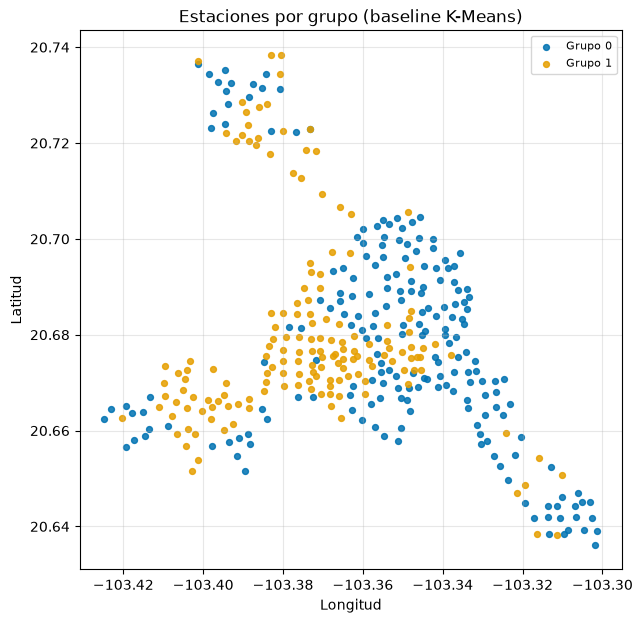

In [9]:
# Ubicación de las estaciones por grupo
mapa = caracteristicas_train.join(nomenclatura.set_index("id")[["name", "latitude", "longitude"]])

fig, ax = plt.subplots(figsize=(7, 7))
for grupo in range(K_ELEGIDO):
    miembros = mapa["grupo"] == grupo
    ax.scatter(mapa.loc[miembros, "longitude"], mapa.loc[miembros, "latitude"], s=18,
               color=colores[grupo], label=f"Grupo {grupo}", alpha=0.85)
ax.set_title("Estaciones por grupo (baseline K-Means)")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.show()

**Observaciones de la evaluación:**
- **Métricas internas:** silueta 0.145, Davies-Bouldin 2.12, Calinski-Harabasz 69.2 e inercia 13,361 para `k = 2`.
- **Estabilidad:** el índice de Rand ajustado entre el grupo de entrenamiento y el reasignado con el año de validación es **0.66** sobre 359 estaciones comunes; 34 (9.5 %) cambian de grupo. La división es moderadamente estable, aunque no inmune al periodo.
- **Interpretación:** el grupo 0 (202 estaciones) tiene un pico matutino dominante a las 8:00 (10.7 % de sus salidas laborales) y su pico de fin de semana a las 10:00; el grupo 1 (160) tiene su pico a las 18:00 (12.6 %). El grupo 1 mueve más viajes (mediana de 29.4 viajes por día contra 19.8) y tiende a perder bicicletas (balance −9.3 % de sus salidas contra +2.9 %). Duración mediana (9.63 min en ambos), proporción de viajes circulares (8.0 % y 7.1 %) y capacidad (15) casi no los distinguen. Las etiquetas 0 y 1 de K-Means son arbitrarias: con los 81 meses quedaron invertidas respecto a una corrida anterior con 79.
- **Ubicación:** el grupo 1 (salida de tarde) está más cerca del centro de la red (distancia mediana de 2.2 km contra 3.0 km del grupo 0) y más al poniente (longitud mediana −103.373 contra −103.350). Hipótesis por verificar: el grupo 0 son estaciones desde donde se sale por la mañana (residenciales) y el grupo 1, desde donde se sale al final de la jornada (zonas de trabajo).
- **Límites del baseline:** la separación se explica casi solo por el perfil horario y el volumen; con `k = 2` la granularidad es insuficiente para decidir dónde ampliar o reubicar. Las 40 variables de perfil pesan mucho más que los 4 indicadores escalares en la distancia. Las estaciones nuevas (109) no se agrupan. Siguientes pasos: PCA o ponderación de variables, `k` de 4 a 5 revisando Davies-Bouldin, y HDBSCAN.

### 4.3.1 Entrega al notebook de mejora

Se guardan las variables por estación (entrenamiento y validación) con el grupo asignado y las métricas del baseline. `0.08-lasd-mejoramodelo-p3` las lee en lugar de repetir el modelo base, de modo que compara contra exactamente este resultado.

In [10]:
# Entrega: variables por estación, grupo del baseline y métricas
import json

RUTA_P3_TRAIN = PROCESSED_DATA_DIR / "p3_caracteristicas_train.parquet"
RUTA_P3_VALID = PROCESSED_DATA_DIR / "p3_caracteristicas_valid.parquet"
RUTA_P3_BASELINE = PROCESSED_DATA_DIR / "p3_baseline.json"

caracteristicas_train.to_parquet(RUTA_P3_TRAIN)
caracteristicas_valid.to_parquet(RUTA_P3_VALID)
RUTA_P3_BASELINE.write_text(json.dumps({
    "k_elegido": int(K_ELEGIDO),
    "metricas": metricas,
    "columnas_modelo": COLUMNAS_MODELO,
    "min_salidas_train": MIN_SALIDAS_TRAIN,
    "min_salidas_valid": MIN_SALIDAS_VALID,
    "k_minimo": K_MINIMO,
    "k_maximo": K_MAXIMO,
}, ensure_ascii=False, indent=1))
print("Guardado en data/processed/:", RUTA_P3_TRAIN.name, RUTA_P3_VALID.name, RUTA_P3_BASELINE.name)

Guardado en data/processed/: p3_caracteristicas_train.parquet p3_caracteristicas_valid.parquet p3_baseline.json


### 4.4 Registro en MLflow

El baseline se registra en el servidor del equipo: experimento `p3`, run `baseline`.
- **Parámetros:** modelo, `k`, semilla, filtros, periodo de entrenamiento y `data_version` (SHA-256 del manifiesto de fuentes).
- **Métricas:** silueta, Davies-Bouldin, Calinski-Harabasz, inercia, estabilidad (ARI) y tamaños de grupo; la silueta por `k` se registra como serie.
- **Etiquetas:** equipo, pregunta, tarea, autor y commit de Git.
- **Artefactos:** asignación de grupo por estación, perfiles, gráficas y el modelo (escalador + K-Means). Se suben por el proxy del servidor (`mlflow-artifacts:/p3`); también quedan en `reports/figures/`.

El experimento se crea con `artifact_location="mlflow-artifacts:/p3"`: si se crea sin esa opción, el servidor asigna una ruta local suya (`/home/ec2-user/...`) y la subida de artefactos falla.

La celda es **idempotente**: si el run `baseline` ya existe en el experimento, no crea otro, para no duplicar corridas al reejecutar el notebook. Se puede forzar uno nuevo con `REGISTRAR_DE_NUEVO = True`.

Solo se registran agregados y datos públicos de estaciones; no hay información de usuarios.

In [ ]:
# Registro del baseline en MLflow (experimento p3, run baseline)
import mlflow
import mlflow.sklearn

URI_MLFLOW = "https://mlflow.equipo7mlops.com/"
EXPERIMENTO = "p3"
NOMBRE_RUN = "baseline"
REGISTRAR_EN_MLFLOW = True
REGISTRAR_DE_NUEVO = False

def commit_actual():
    try:
        return subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], cwd=PROJ_ROOT, text=True).strip()
    except Exception:
        return "desconocido"

RUTA_FIGURAS = FIGURES_DIR

if not REGISTRAR_EN_MLFLOW:
    print("Registro desactivado (REGISTRAR_EN_MLFLOW = False)")
else:
    mlflow.set_tracking_uri(URI_MLFLOW)
    existentes = []
    experimento = mlflow.get_experiment_by_name(EXPERIMENTO)
    # El experimento debe guardar los artefactos por el proxy del servidor (mlflow-artifacts:/);
    # si apunta a una ruta local del servidor, el cliente no puede escribir en ella.
    if experimento is None:
        mlflow.create_experiment(EXPERIMENTO, artifact_location="mlflow-artifacts:/" + EXPERIMENTO)
        experimento = mlflow.get_experiment_by_name(EXPERIMENTO)
    assert experimento.artifact_location.startswith("mlflow-artifacts:"), (
        "El experimento no usa el proxy de artefactos: " + experimento.artifact_location)
    if experimento is not None:
        existentes = mlflow.search_runs(experiment_ids=[experimento.experiment_id],
                                        filter_string=f"tags.mlflow.runName = '{NOMBRE_RUN}'")
    if len(existentes) and not REGISTRAR_DE_NUEVO:
        print(f"Ya existe un run '{NOMBRE_RUN}' en el experimento '{EXPERIMENTO}': "
              f"{URI_MLFLOW}#/experiments/{experimento.experiment_id}/runs/{existentes.iloc[0]['run_id']}")
    else:
        # Artefactos locales: asignación por estación, perfiles, variables y gráficas
        asignacion = (mapa[["name", "latitude", "longitude", "grupo", "salidas"]]
                      .rename(columns={"name": "estacion", "salidas": "salidas_train"}))
        asignacion.to_csv(RUTA_FIGURAS / "p3_asignacion_grupos.csv", index_label="estacion_id")
        resumen_grupos.to_csv(RUTA_FIGURAS / "p3_resumen_grupos.csv")
        (RUTA_FIGURAS / "p3_variables.json").write_text(json.dumps(COLUMNAS_MODELO, ensure_ascii=False, indent=1))

        fig_k, ejes_k = plt.subplots(figsize=(6, 3.5))
        resultados_k["silueta"].plot(marker="o", ax=ejes_k, color=AZUL)
        ejes_k.axvline(K_ELEGIDO, color=NARANJA, linestyle="--")
        ejes_k.set_title("Silueta por k")
        ejes_k.set_xlabel("k")
        fig_k.tight_layout()
        fig_k.savefig(RUTA_FIGURAS / "p3_silueta_por_k.png", dpi=150)
        plt.close(fig_k)

        fig_m, eje_m = plt.subplots(figsize=(7, 7))
        for grupo in range(K_ELEGIDO):
            miembros = mapa["grupo"] == grupo
            eje_m.scatter(mapa.loc[miembros, "longitude"], mapa.loc[miembros, "latitude"], s=18,
                          color=colores[grupo], label=f"Grupo {grupo}")
        eje_m.set_title("Estaciones por grupo (baseline)")
        eje_m.legend(fontsize=8)
        fig_m.savefig(RUTA_FIGURAS / "p3_mapa_grupos.png", dpi=150)
        plt.close(fig_m)

        mlflow.set_experiment(EXPERIMENTO)
        with mlflow.start_run(run_name=NOMBRE_RUN) as corrida:
            mlflow.set_tags({
                "equipo": "7", "pregunta": "P3", "tarea": "clustering", "autor": "lasd",
                "commit": commit_actual(), "notebook": "0.03-lasd-exploracion-carga",
                "etapa": "baseline",
            })
            mlflow.log_params({
                "modelo": "StandardScaler + KMeans",
                "k": K_ELEGIDO, "k_minimo": K_MINIMO, "k_maximo": K_MAXIMO, "n_init": 10,
                "semilla": SEMILLA,
                "rango_datos": f"{MES_INICIO} a {MES_FIN}",
                "periodo_train": "2020-01-01 a 2024-09-29",
                "periodo_estabilidad": "2024-10-01 a 2025-09-29",
                "min_salidas_train": MIN_SALIDAS_TRAIN, "min_salidas_valid": MIN_SALIDAS_VALID,
                "n_variables": len(COLUMNAS_MODELO),
                "horas_excluidas": "1-4",
                "data_version": dataset.version_datos(),
            })
            for k, fila in resultados_k.iterrows():
                mlflow.log_metric("silueta_por_k", float(fila["silueta"]), step=int(k))
            mlflow.log_metrics(metricas)
            mlflow.log_artifacts(str(RUTA_FIGURAS), artifact_path="p3")
            mlflow.sklearn.log_model(modelo_base, name="modelo",
                                     input_example=X_train.head(3))
        print("Run registrado:", f"{URI_MLFLOW}#/experiments/{corrida.info.experiment_id}/runs/{corrida.info.run_id}")